In [1]:


from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connected successfully! ")

Mounted at /content/drive
Google Drive connected successfully! 


In [2]:


import os

print("My Drive contents:")
print(os.listdir('/content/drive/MyDrive'))

My Drive contents:
['Colab Notebooks', '20220807_111824.jpg', '20220819_151411.jpg', '20220904_111340.jpg', 'Screenshot_20221010-171017_Word.jpg', '20221106_190941.jpg', '20221218_122300.jpg', 'Screenshot_20230118-163630_Word.jpg', '20230215_212759 (1).jpg', '20230215_212759.jpg', 'IMG-20230326-WA0074 (1).jpg', 'IMG-20230326-WA0074.jpg', '20230411_113111.jpg', 'Screenshot_20230509-154221_CamScanner.jpg', '20230526_062644.jpg', '20230531_001355.jpg', '20230630_223044 (1).jpg', '20230630_223044.jpg', '20230811_181813.jpg', 'Screenshot_20230817-161234_Chrome (1).jpg', 'Screenshot_20230817-161234_Chrome.jpg', 'IMG-20230929-WA0017.jpg', 'Resume.gdoc', 'Untitled document (7).gdoc', 'AIDS.pdf', 'AIDS (1).gdoc', 'AIDS.docx', 'AIDS.gdoc', 'Hello.gdoc', 'Untitled document (6).gdoc', 'Untitled document (5).gdoc', 'Untitled document (3).docx', 'Untitled document (2).docx', 'Screenshot_20231215-220414_Word.jpg', '17026581783391454671645966243619.jpg', 'Chromebook Wallpaper', '9709_w23_qp_52.pdf', '

In [3]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Crop Disease AI project"

print("Contents of Crop Disease AI project:")
print(os.listdir(PROJECT_DIR))

Contents of Crop Disease AI project:
['Member 06', 'Member 07', '02_Group_Pipeline', '03_Final_Output', '04_Documentation', 'Member 02_IT25103229', 'Member 01_IT25103233', 'Member 05_IT25103052', 'Member 05', 'Member IT25103567', 'Member_03_IT25103371']


In [4]:
MEMBER02_DIR = (
    "/content/drive/MyDrive/Crop Disease AI project/"
    "Member 02_IT25103229"
)

print("Member 02 contents:")
print(os.listdir(MEMBER02_DIR))

Member 02 contents:
['Notebook', 'EDA', 'Outputs']


In [5]:
MEMBER02_OUTPUTS = (
    "/content/drive/MyDrive/Crop Disease AI project/"
    "Member 02_IT25103229/Outputs"
)

print("Member 02 Outputs:")
print(os.listdir(MEMBER02_OUTPUTS))

Member 02 Outputs:
['validation_normalized_images.npy', 'train_normalized_images.npy', 'train_labels.npy', 'train_filepaths.npy', 'validation_labels.npy', 'validation_filepaths.npy']


In [6]:
import os

TRAIN_IMAGES_PATH = (
    "/content/drive/MyDrive/Crop Disease AI project/"
    "Member 02_IT25103229/Outputs/"
    "train_normalized_images.npy"
)

TRAIN_LABELS_PATH = (
    "/content/drive/MyDrive/Crop Disease AI project/"
    "Member 02_IT25103229/Outputs/"
    "train_labels.npy"
)

print("Training images file exists:",
      os.path.exists(TRAIN_IMAGES_PATH))

print("Training labels file exists:",
      os.path.exists(TRAIN_LABELS_PATH))

print(
    "\nTraining images size:",
    round(os.path.getsize(TRAIN_IMAGES_PATH) / (1024**3), 2),
    "GB"
)

print(
    "Training labels size:",
    round(os.path.getsize(TRAIN_LABELS_PATH) / (1024**2), 2),
    "MB"
)

Training images file exists: True
Training labels file exists: True

Training images size: 6.54 GB
Training labels size: 1.16 MB


In [8]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)

NumPy: 2.1.3
TensorFlow: 2.20.0


In [9]:


TRAIN_IMAGES_PATH = (
    "/content/drive/MyDrive/Crop Disease AI project/"
    "Member 02_IT25103229/Outputs/"
    "train_normalized_images.npy"
)

TRAIN_LABELS_PATH = (
    "/content/drive/MyDrive/Crop Disease AI project/"
    "Member 02_IT25103229/Outputs/"
    "train_labels.npy"
)

print("Training images path:")
print(TRAIN_IMAGES_PATH)

print("\nTraining labels path:")
print(TRAIN_LABELS_PATH)

Training images path:
/content/drive/MyDrive/Crop Disease AI project/Member 02_IT25103229/Outputs/train_normalized_images.npy

Training labels path:
/content/drive/MyDrive/Crop Disease AI project/Member 02_IT25103229/Outputs/train_labels.npy


In [10]:


train_images = np.load(
    TRAIN_IMAGES_PATH,
    mmap_mode="r"
)

train_labels = np.load(
    TRAIN_LABELS_PATH
)

print("Training images shape:")
print(train_images.shape)

print("\nTraining labels shape:")
print(train_labels.shape)

print("\nImage data type:")
print(train_images.dtype)

Training images shape:
(11662, 224, 224, 3)

Training labels shape:
(11662,)

Image data type:
float32


In [11]:
train_images = np.load(
    TRAIN_IMAGES_PATH,
    mmap_mode="r"
)

train_labels = np.load(
    TRAIN_LABELS_PATH
)

print("Training images shape:")
print(train_images.shape)

print("\nTraining labels shape:")
print(train_labels.shape)

print("\nImage data type:")
print(train_images.dtype)

print("\nLabel data type:")
print(train_labels.dtype)

Training images shape:
(11662, 224, 224, 3)

Training labels shape:
(11662,)

Image data type:
float32

Label data type:
<U26


In [12]:
# Check pixel value range using a small sample
sample_images = train_images[:100]

print("Minimum pixel value:", sample_images.min())
print("Maximum pixel value:", sample_images.max())

# Check unique disease classes
unique_classes = np.unique(train_labels)

print("\nNumber of unique classes:", len(unique_classes))

print("\nDisease classes:")
for i, class_name in enumerate(unique_classes):
    print(i, ":", class_name)

Minimum pixel value: 0.0
Maximum pixel value: 1.0

Number of unique classes: 20

Disease classes:
0 : Becterial Blight in Rice
1 : Brownspot
2 : Gray_Leaf_Spot
3 : Healthy Maize
4 : Healthy Wheat
5 : Healthy cotton
6 : Mosaic sugarcane
7 : RedRot sugarcane
8 : Rice Blast
9 : Sugarcane Healthy
10 : Tungro
11 : Wheat Stem fly
12 : Wheat black rust
13 : Wheat powdery mildew
14 : Wilt
15 : bacterial_blight in Cotton
16 : cotton mealy bug
17 : maize fall armyworm
18 : maize stem borer
19 : red cotton bug


In [13]:
from collections import Counter

# Count images in each class
class_counts = Counter(train_labels)

# Create a dataframe
class_distribution = pd.DataFrame(
    {
        "Class": list(class_counts.keys()),
        "Image_Count": list(class_counts.values())
    }
)

# Sort by image count
class_distribution = class_distribution.sort_values(
    "Image_Count",
    ascending=False
).reset_index(drop=True)

print("Training class distribution:")
display(class_distribution)

print("\nLargest class:")
print(class_distribution.iloc[0])

print("\nSmallest class:")
print(class_distribution.iloc[-1])

Training class distribution:


,Class,Image_Count
0,Brownspot,1640
1,Becterial Blight in Rice,1584
2,Rice Blast,1440
3,Tungro,1308
4,Healthy Maize,1162
5,RedRot sugarcane,592
6,Gray_Leaf_Spot,574
7,Sugarcane Healthy,522
8,bacterial_blight in Cotton,489
9,Mosaic sugarcane,462



Largest class:
Class          Brownspot
Image_Count         1640
Name: 0, dtype: object

Smallest class:
Class          red cotton bug
Image_Count                69
Name: 19, dtype: object


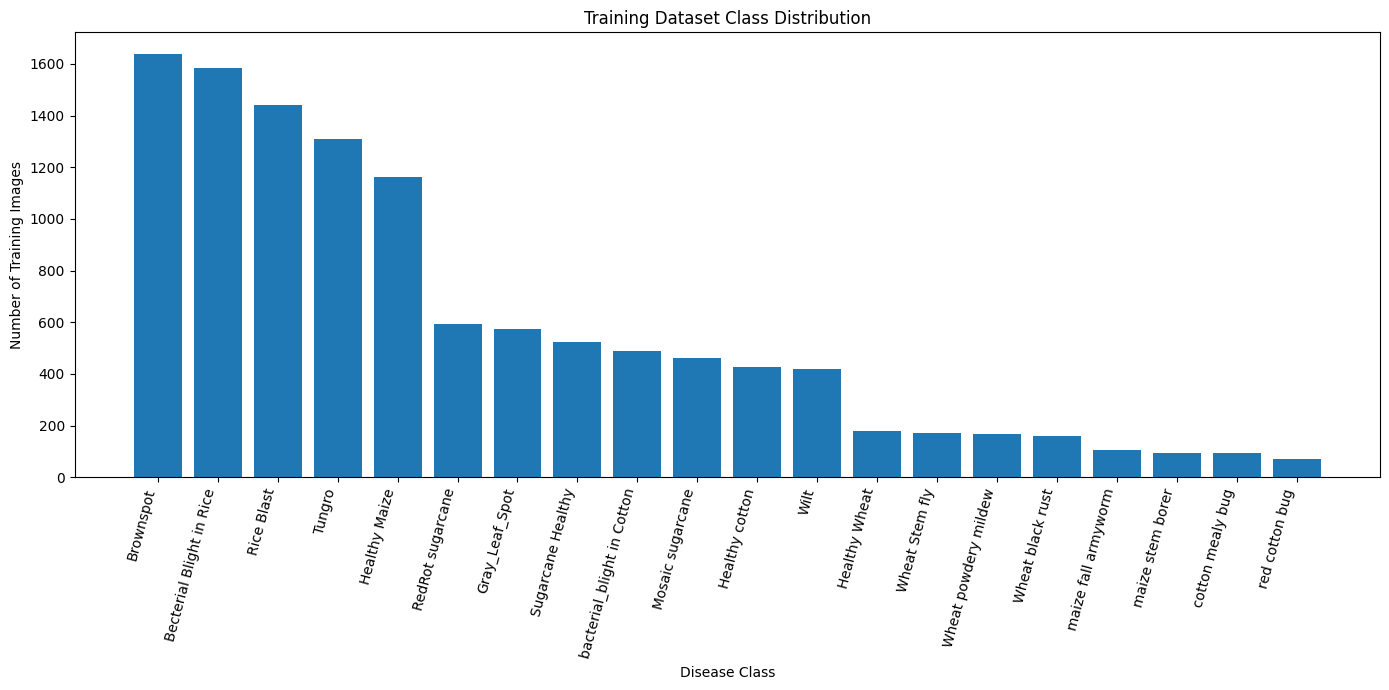

In [14]:
plt.figure(figsize=(14, 7))

plt.bar(
    class_distribution["Class"],
    class_distribution["Image_Count"]
)

plt.xticks(
    rotation=75,
    ha="right"
)

plt.xlabel("Disease Class")
plt.ylabel("Number of Training Images")
plt.title("Training Dataset Class Distribution")

plt.tight_layout()
plt.show()

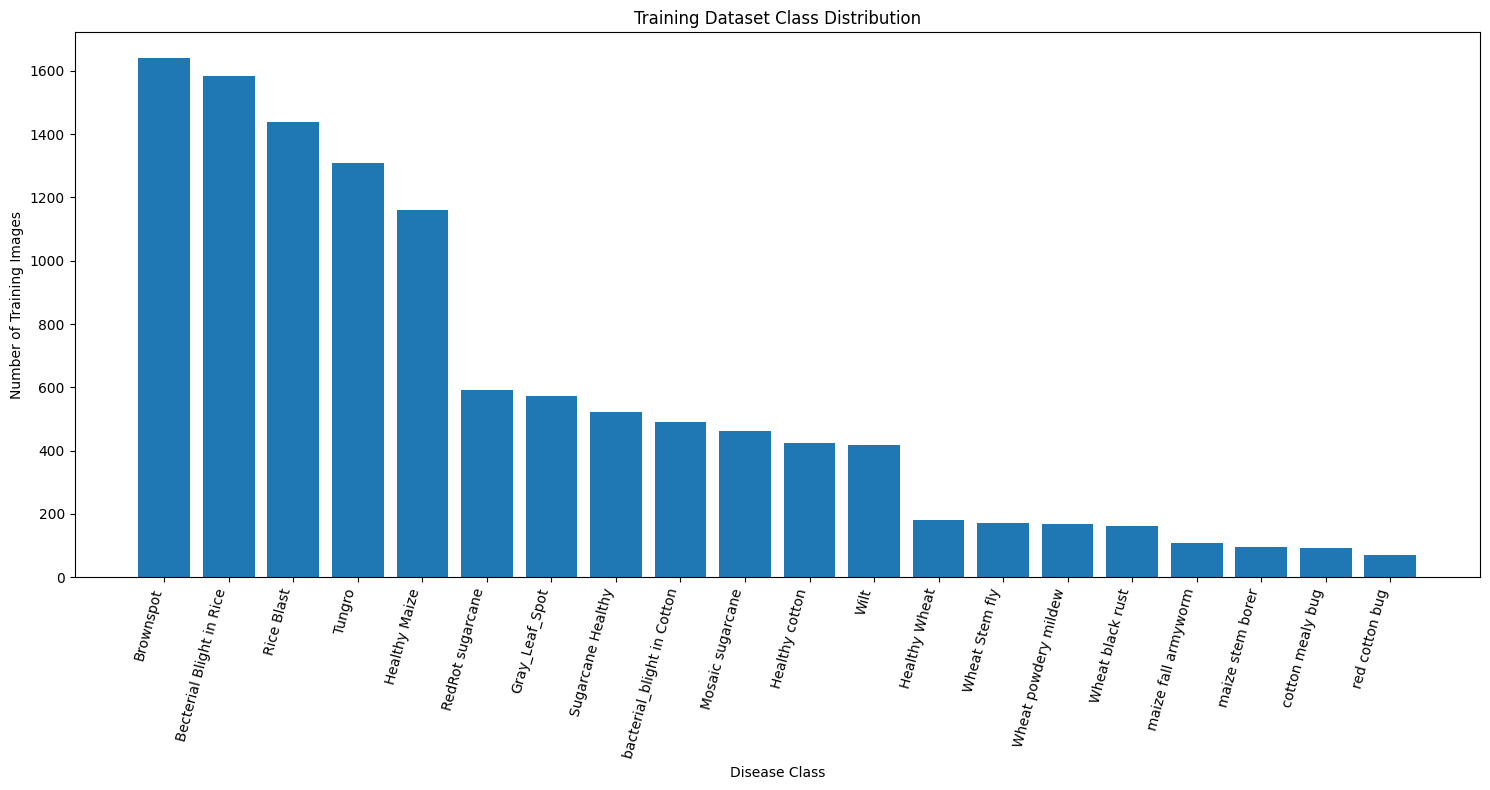

Saved EDA chart to:
/content/drive/MyDrive/Crop Disease AI project/Member 02_IT25103229/EDA/training_class_distribution.png


In [15]:
# Create and save the class distribution EDA chart

EDA_PATH = (
    "/content/drive/MyDrive/Crop Disease AI project/"
    "Member 02_IT25103229/EDA"
)

import os
os.makedirs(EDA_PATH, exist_ok=True)

plt.figure(figsize=(15, 8))

plt.bar(
    class_distribution["Class"],
    class_distribution["Image_Count"]
)

plt.xticks(
    rotation=75,
    ha="right"
)

plt.xlabel("Disease Class")
plt.ylabel("Number of Training Images")
plt.title("Training Dataset Class Distribution")

plt.tight_layout()

distribution_plot_path = os.path.join(
    EDA_PATH,
    "training_class_distribution.png"
)

plt.savefig(
    distribution_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved EDA chart to:")
print(distribution_plot_path)

In [16]:
# Categorize classes based on training image count

def imbalance_category(count):
    if count < 200:
        return "Severe minority"
    elif count < 500:
        return "Minority"
    elif count < 1000:
        return "Moderate"
    else:
        return "Majority"

class_distribution["Imbalance_Category"] = (
    class_distribution["Image_Count"]
    .apply(imbalance_category)
)

display(class_distribution)

,Class,Image_Count,Imbalance_Category
0,Brownspot,1640,Majority
1,Becterial Blight in Rice,1584,Majority
2,Rice Blast,1440,Majority
3,Tungro,1308,Majority
4,Healthy Maize,1162,Majority
5,RedRot sugarcane,592,Moderate
6,Gray_Leaf_Spot,574,Moderate
7,Sugarcane Healthy,522,Moderate
8,bacterial_blight in Cotton,489,Minority
9,Mosaic sugarcane,462,Minority


In [17]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(
        mode="horizontal"
    ),
    tf.keras.layers.RandomRotation(
        factor=0.10
    ),
    tf.keras.layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10
    ),
    tf.keras.layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10
    )
])

print("Data augmentation pipeline created successfully!")

Data augmentation pipeline created successfully!


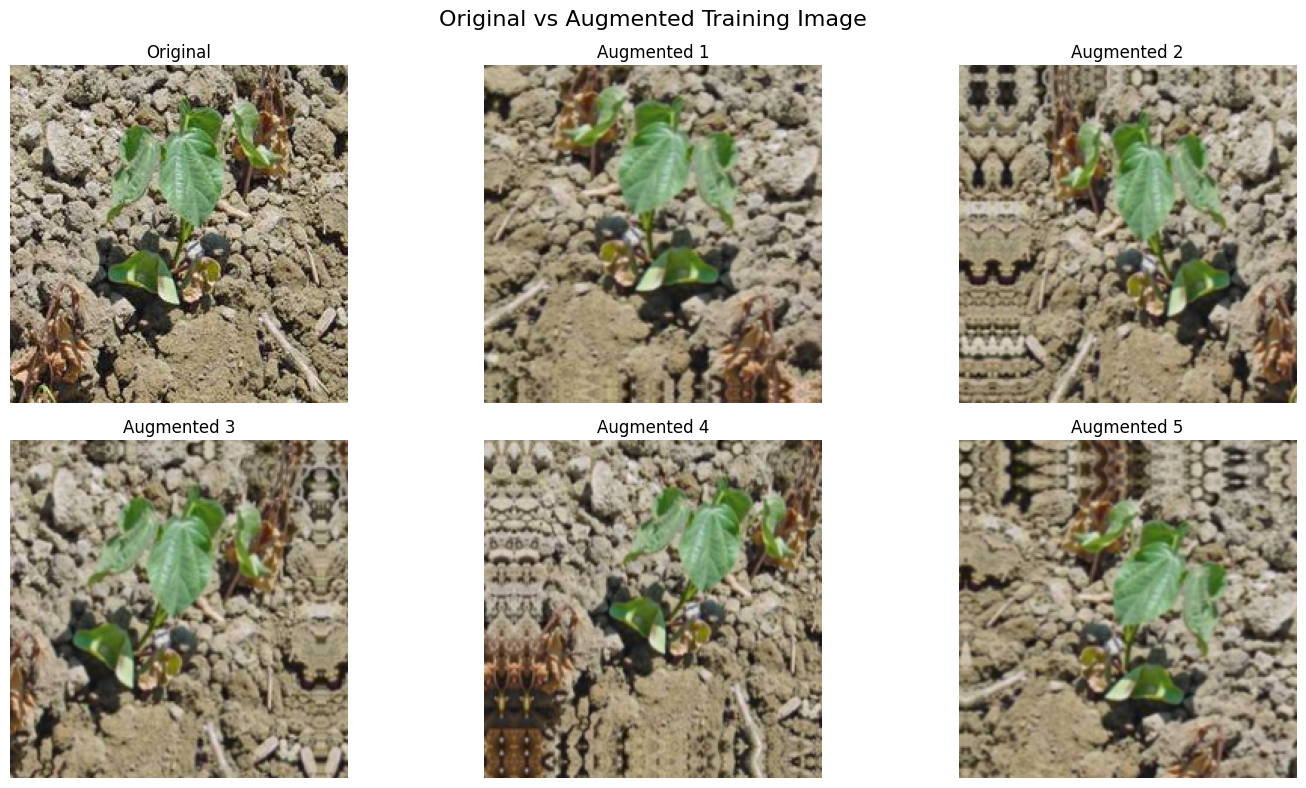

In [19]:
# Select one training image
original_image = train_images[0]

# Convert to TensorFlow tensor
image_tensor = tf.convert_to_tensor(
    original_image,
    dtype=tf.float32
)

# Add batch dimension
image_tensor = tf.expand_dims(
    image_tensor,
    axis=0
)

# Repeat the same image 5 times
image_batch = tf.repeat(
    image_tensor,
    repeats=5,
    axis=0
)

# Apply augmentation to all 5 images
augmented_images = data_augmentation(
    image_batch,
    training=True
).numpy()

# Plot original + 5 augmented versions
plt.figure(figsize=(15, 8))

# Original
plt.subplot(2, 3, 1)
plt.imshow(original_image)
plt.title("Original")
plt.axis("off")

# Augmented images
for i in range(5):
    plt.subplot(2, 3, i + 2)
    plt.imshow(augmented_images[i])
    plt.title(f"Augmented {i + 1}")
    plt.axis("off")

plt.suptitle(
    "Original vs Augmented Training Image",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [20]:
import os

MEMBER_WORK_PATH = (
    "/content/drive/MyDrive/Crop Disease AI project/"
    "01_Member_Work"
)

print(os.listdir(MEMBER_WORK_PATH))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Crop Disease AI project/01_Member_Work'

In [21]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Crop Disease AI project"

print("Folders/files inside project:")
for item in os.listdir(PROJECT_PATH):
    print("📁", item)

Folders/files inside project:
📁 Member 06
📁 Member 07
📁 02_Group_Pipeline
📁 03_Final_Output
📁 04_Documentation
📁 Member 02_IT25103229
📁 Member 01_IT25103233
📁 Member 05_IT25103052
📁 Member 05
📁 Member IT25103567
📁 Member_03_IT25103371


In [22]:
import os

MEMBER3_PATH = (
    "/content/drive/MyDrive/Crop Disease AI project/"
    "Member_03_IT25103371"
)

print("Member 3 folder contents:")

for item in os.listdir(MEMBER3_PATH):
    print("📁", item)

Member 3 folder contents:
📁 Notebook
📁 Code
📁 EDA
📁 Outputs


In [23]:
import os

# Your Member 3 folders
MEMBER3_PATH = (
    "/content/drive/MyDrive/Crop Disease AI project/"
    "Member_03_IT25103371"
)

MEMBER3_EDA = os.path.join(MEMBER3_PATH, "EDA")
MEMBER3_OUTPUTS = os.path.join(MEMBER3_PATH, "Outputs")

# Make sure the folders exist
os.makedirs(MEMBER3_EDA, exist_ok=True)
os.makedirs(MEMBER3_OUTPUTS, exist_ok=True)

print("✅ Member 3 EDA folder:")
print(MEMBER3_EDA)

print("\n✅ Member 3 Outputs folder:")
print(MEMBER3_OUTPUTS)

✅ Member 3 EDA folder:
/content/drive/MyDrive/Crop Disease AI project/Member_03_IT25103371/EDA

✅ Member 3 Outputs folder:
/content/drive/MyDrive/Crop Disease AI project/Member_03_IT25103371/Outputs


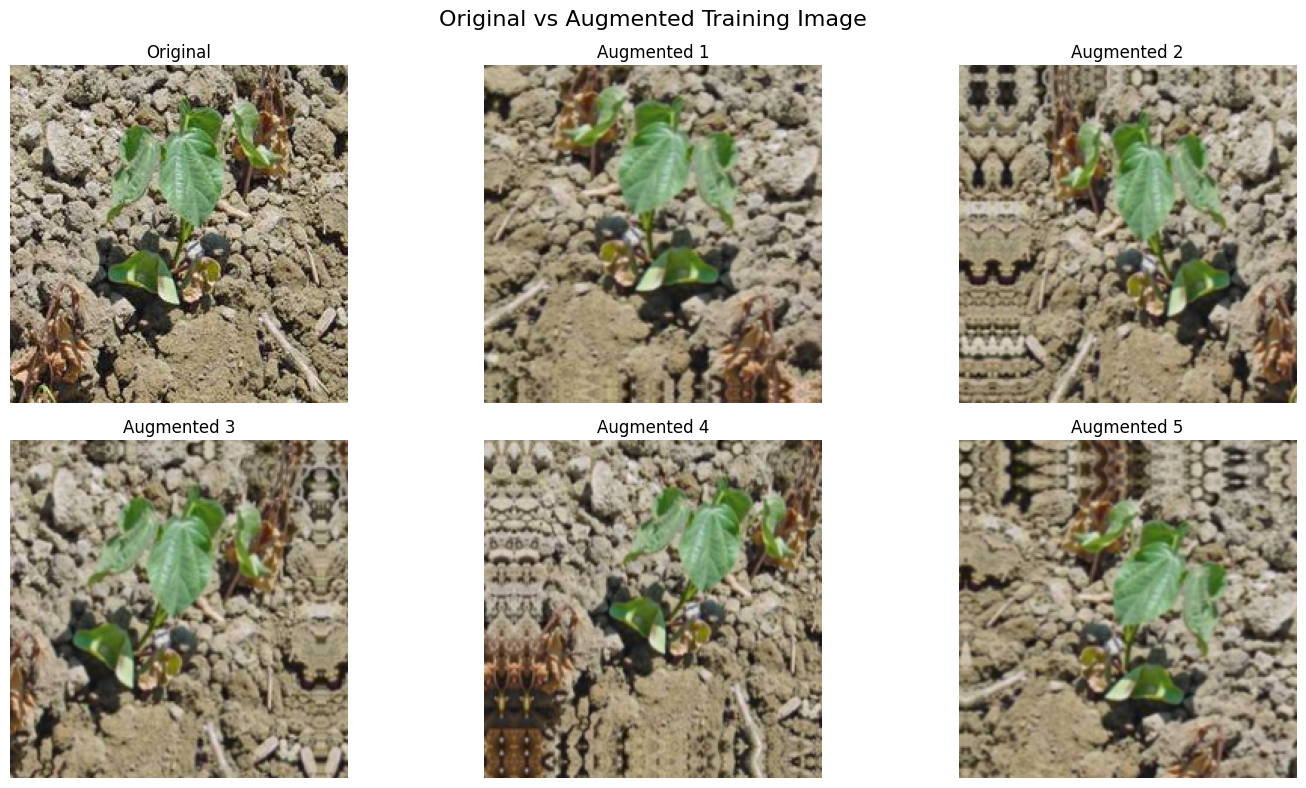

✅ EDA saved successfully!
/content/drive/MyDrive/Crop Disease AI project/Member_03_IT25103371/EDA/original_vs_augmented.png


In [24]:
# Save Original vs Augmented comparison to YOUR EDA folder

original_vs_augmented_path = os.path.join(
    MEMBER3_EDA,
    "original_vs_augmented.png"
)

plt.figure(figsize=(15, 8))

# Original
plt.subplot(2, 3, 1)
plt.imshow(original_image)
plt.title("Original")
plt.axis("off")

# Augmented versions
for i in range(5):
    plt.subplot(2, 3, i + 2)
    plt.imshow(augmented_images[i])
    plt.title(f"Augmented {i + 1}")
    plt.axis("off")

plt.suptitle(
    "Original vs Augmented Training Image",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    original_vs_augmented_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ EDA saved successfully!")
print(original_vs_augmented_path)

In [25]:
import os

MEMBER3_PATH = (
    "/content/drive/MyDrive/Crop Disease AI project/"
    "Member_03_IT25103371"
)

MEMBER3_EDA = os.path.join(MEMBER3_PATH, "EDA")
MEMBER3_OUTPUTS = os.path.join(MEMBER3_PATH, "Outputs")
MEMBER3_CODE = os.path.join(MEMBER3_PATH, "Code")

os.makedirs(MEMBER3_EDA, exist_ok=True)
os.makedirs(MEMBER3_OUTPUTS, exist_ok=True)
os.makedirs(MEMBER3_CODE, exist_ok=True)

print("✅ Member 3 paths ready!")
print("EDA:", MEMBER3_EDA)
print("Outputs:", MEMBER3_OUTPUTS)
print("Code:", MEMBER3_CODE)

✅ Member 3 paths ready!
EDA: /content/drive/MyDrive/Crop Disease AI project/Member_03_IT25103371/EDA
Outputs: /content/drive/MyDrive/Crop Disease AI project/Member_03_IT25103371/Outputs
Code: /content/drive/MyDrive/Crop Disease AI project/Member_03_IT25103371/Code


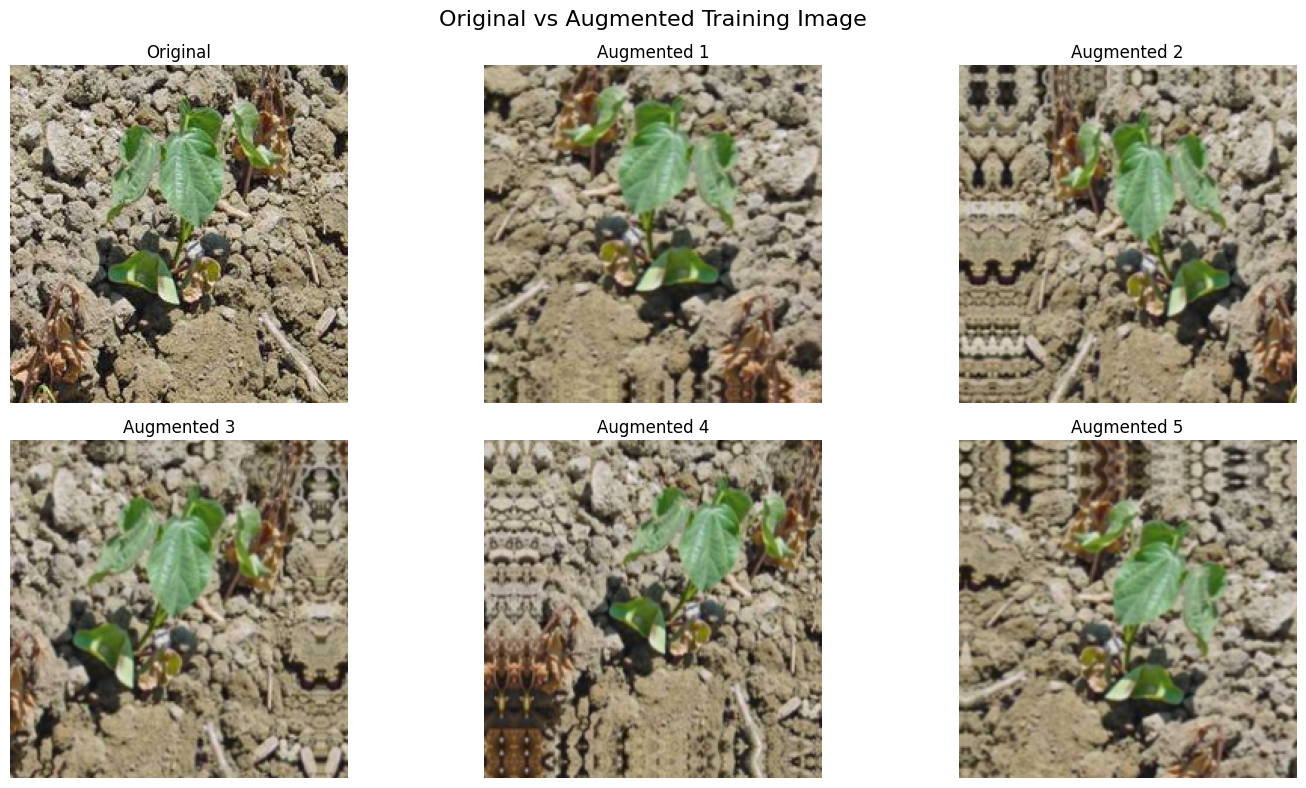

✅ EDA saved!
/content/drive/MyDrive/Crop Disease AI project/Member_03_IT25103371/EDA/original_vs_augmented.png


In [26]:
# Save Original vs Augmented comparison in MEMBER 3's EDA folder

original_vs_augmented_path = os.path.join(
    MEMBER3_EDA,
    "original_vs_augmented.png"
)

plt.figure(figsize=(15, 8))

# Original
plt.subplot(2, 3, 1)
plt.imshow(original_image)
plt.title("Original")
plt.axis("off")

# Augmented images
for i in range(5):
    plt.subplot(2, 3, i + 2)
    plt.imshow(augmented_images[i])
    plt.title(f"Augmented {i + 1}")
    plt.axis("off")

plt.suptitle(
    "Original vs Augmented Training Image",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    original_vs_augmented_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ EDA saved!")
print(original_vs_augmented_path)

In [27]:
# ============================================
# MEMBER 3 - TRAINING DATA AUGMENTATION
# ============================================

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(
        mode="horizontal"
    ),

    tf.keras.layers.RandomRotation(
        factor=0.10
    ),

    tf.keras.layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10
    ),

    tf.keras.layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10
    )
])

print("✅ Training augmentation pipeline created!")
print()
print("Augmentations:")
print("1. Horizontal Flip")
print("2. Random Rotation")
print("3. Random Zoom")
print("4. Random Translation")

✅ Training augmentation pipeline created!

Augmentations:
1. Horizontal Flip
2. Random Rotation
3. Random Zoom
4. Random Translation


In [28]:
# Test augmentation on a small batch

test_batch = train_images[:8]

test_batch_tensor = tf.convert_to_tensor(
    test_batch,
    dtype=tf.float32
)

augmented_batch = data_augmentation(
    test_batch_tensor,
    training=True
)

print("Original batch shape:")
print(test_batch.shape)

print("\nAugmented batch shape:")
print(augmented_batch.shape)

print("\nOriginal pixel range:")
print(
    float(test_batch.min()),
    "to",
    float(test_batch.max())
)

print("\nAugmented pixel range:")
print(
    float(tf.reduce_min(augmented_batch)),
    "to",
    float(tf.reduce_max(augmented_batch))
)

Original batch shape:
(8, 224, 224, 3)

Augmented batch shape:
(8, 224, 224, 3)

Original pixel range:
0.0 to 1.0

Augmented pixel range:
0.0025953748263418674 to 1.0


In [29]:


def image_generator():
    for i in range(len(train_images)):
        yield train_images[i], train_labels[i]


# Image shape
image_shape = train_images.shape[1:]

# Create TensorFlow dataset
dataset = tf.data.Dataset.from_generator(
    image_generator,
    output_signature=(
        tf.TensorSpec(
            shape=image_shape,
            dtype=tf.float32
        ),
        tf.TensorSpec(
            shape=(),
            dtype=tf.string
        )
    )
)

print("✅ Base TensorFlow dataset created!")
print("Image shape:", image_shape)

✅ Base TensorFlow dataset created!
Image shape: (224, 224, 3)


In [30]:
BATCH_SIZE = 32

augmented_train_dataset = (
    dataset
    .shuffle(
        buffer_size=1000,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .map(
        lambda images, labels: (
            data_augmentation(
                images,
                training=True
            ),
            labels
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .prefetch(tf.data.AUTOTUNE)
)

print("✅ Augmented training pipeline created!")
print("Batch size:", BATCH_SIZE)

✅ Augmented training pipeline created!
Batch size: 32


In [31]:
# Take one batch from the augmented dataset

images_batch, labels_batch = next(
    iter(augmented_train_dataset)
)

print("Batch image shape:")
print(images_batch.shape)

print("\nBatch label shape:")
print(labels_batch.shape)

print("\nFirst 5 labels:")
print(labels_batch[:5].numpy())

print("\nAugmented pixel range:")
print(
    float(tf.reduce_min(images_batch)),
    "to",
    float(tf.reduce_max(images_batch))
)

Batch image shape:
(32, 224, 224, 3)

Batch label shape:
(32,)

First 5 labels:
[b'Wilt' b'Wilt' b'Tungro' b'Tungro' b'Tungro']

Augmented pixel range:
0.0 to 1.0


In [32]:

TARGET_COUNT = 500

class_distribution["Additional_Images_Needed"] = (
    TARGET_COUNT - class_distribution["Image_Count"]
).clip(lower=0)

class_distribution["Needs_Targeted_Augmentation"] = (
    class_distribution["Image_Count"] < TARGET_COUNT
)

print("Target count:", TARGET_COUNT)
print()

display(
    class_distribution[
        [
            "Class",
            "Image_Count",
            "Additional_Images_Needed",
            "Needs_Targeted_Augmentation"
        ]
    ]
)

Target count: 500



,Class,Image_Count,Additional_Images_Needed,Needs_Targeted_Augmentation
0,Brownspot,1640,0,False
1,Becterial Blight in Rice,1584,0,False
2,Rice Blast,1440,0,False
3,Tungro,1308,0,False
4,Healthy Maize,1162,0,False
5,RedRot sugarcane,592,0,False
6,Gray_Leaf_Spot,574,0,False
7,Sugarcane Healthy,522,0,False
8,bacterial_blight in Cotton,489,11,True
9,Mosaic sugarcane,462,38,True


In [33]:
minority_classes = class_distribution[
    class_distribution["Needs_Targeted_Augmentation"]
]

print(
    "Number of classes needing targeted augmentation:",
    len(minority_classes)
)

print(
    "Total additional augmented samples needed to reach",
    TARGET_COUNT,
    ":",
    int(minority_classes["Additional_Images_Needed"].sum())
)

Number of classes needing targeted augmentation: 12
Total additional augmented samples needed to reach 500 : 3160


In [34]:


targeted_plan = class_distribution[
    class_distribution["Image_Count"] < TARGET_COUNT
].copy()

targeted_plan = targeted_plan[
    [
        "Class",
        "Image_Count",
        "Additional_Images_Needed"
    ]
].sort_values(
    "Image_Count",
    ascending=True
).reset_index(drop=True)

print("🌱 Targeted Augmentation Plan")
print("Target:", TARGET_COUNT, "images per minority class")
print()

display(targeted_plan)

🌱 Targeted Augmentation Plan
Target: 500 images per minority class



,Class,Image_Count,Additional_Images_Needed
0,red cotton bug,69,431
1,cotton mealy bug,92,408
2,maize stem borer,95,405
3,maize fall armyworm,107,393
4,Wheat black rust,161,339
5,Wheat powdery mildew,169,331
6,Wheat Stem fly,172,328
7,Healthy Wheat,180,320
8,Wilt,419,81
9,Healthy cotton,425,75


In [35]:
# Save targeted augmentation analysis

targeted_plan_path = os.path.join(
    MEMBER3_EDA,
    "targeted_augmentation_plan.csv"
)

targeted_plan.to_csv(
    targeted_plan_path,
    index=False
)

print("✅ Targeted augmentation plan saved!")
print(targeted_plan_path)

✅ Targeted augmentation plan saved!
/content/drive/MyDrive/Crop Disease AI project/Member_03_IT25103371/EDA/targeted_augmentation_plan.csv


In [36]:
# ============================================
# MEMBER 3 - MINORITY CLASS INDICES
# ============================================

minority_classes = targeted_plan["Class"].tolist()

minority_indices = np.where(
    np.isin(train_labels, minority_classes)
)[0]

print("Number of minority-class images:", len(minority_indices))

print("\nMinority classes:")
for class_name in minority_classes:
    count = np.sum(train_labels == class_name)
    print(f"{class_name}: {count} images")

Number of minority-class images: 2840

Minority classes:
red cotton bug: 69 images
cotton mealy bug: 92 images
maize stem borer: 95 images
maize fall armyworm: 107 images
Wheat black rust: 161 images
Wheat powdery mildew: 169 images
Wheat Stem fly: 172 images
Healthy Wheat: 180 images
Wilt: 419 images
Healthy cotton: 425 images
Mosaic sugarcane: 462 images
bacterial_blight in Cotton: 489 images


In [37]:
# ============================================
# MEMBER 3 - TARGETED AUGMENTATION OUTPUT
# ============================================

TARGETED_AUG_PATH = os.path.join(
    MEMBER3_OUTPUTS,
    "targeted_augmented_images"
)

os.makedirs(
    TARGETED_AUG_PATH,
    exist_ok=True
)

print("✅ Targeted augmentation output folder ready:")
print(TARGETED_AUG_PATH)

✅ Targeted augmentation output folder ready:
/content/drive/MyDrive/Crop Disease AI project/Member_03_IT25103371/Outputs/targeted_augmented_images


In [38]:
# ============================================
# GENERATE TARGETED AUGMENTED SAMPLES
# ============================================

generated_total = 0

for _, row in targeted_plan.iterrows():

    class_name = row["Class"]
    original_count = int(row["Image_Count"])
    additional_needed = int(row["Additional_Images_Needed"])

    # Get indices belonging to this class
    class_indices = np.where(
        train_labels == class_name
    )[0]

    class_output_path = os.path.join(
        TARGETED_AUG_PATH,
        class_name.replace("/", "_")
    )

    os.makedirs(
        class_output_path,
        exist_ok=True
    )

    print(
        f"\n🌱 {class_name}"
        f" | Original: {original_count}"
        f" | Generating: {additional_needed}"
    )

    generated_for_class = 0

    while generated_for_class < additional_needed:

        # Randomly select an original image from this class
        idx = np.random.choice(class_indices)

        image = train_images[idx]

        # Convert image to TensorFlow tensor
        image_tensor = tf.convert_to_tensor(
            image,
            dtype=tf.float32
        )

        # Add batch dimension
        image_tensor = tf.expand_dims(
            image_tensor,
            axis=0
        )

        # Apply random augmentation
        augmented = data_augmentation(
            image_tensor,
            training=True
        )[0].numpy()

        # Save as individual .npy file
        output_file = os.path.join(
            class_output_path,
            f"aug_{generated_for_class:04d}.npy"
        )

        np.save(
            output_file,
            augmented.astype(np.float32)
        )

        generated_for_class += 1
        generated_total += 1

    print(
        f"   ✅ Generated {generated_for_class}"
    )

print("\n===================================")
print("🎉 TARGETED AUGMENTATION COMPLETE")
print("===================================")
print("Total generated:", generated_total)


🌱 red cotton bug | Original: 69 | Generating: 431
   ✅ Generated 431

🌱 cotton mealy bug | Original: 92 | Generating: 408
   ✅ Generated 408

🌱 maize stem borer | Original: 95 | Generating: 405
   ✅ Generated 405

🌱 maize fall armyworm | Original: 107 | Generating: 393
   ✅ Generated 393

🌱 Wheat black rust | Original: 161 | Generating: 339
   ✅ Generated 339

🌱 Wheat powdery mildew | Original: 169 | Generating: 331
   ✅ Generated 331

🌱 Wheat Stem fly | Original: 172 | Generating: 328
   ✅ Generated 328

🌱 Healthy Wheat | Original: 180 | Generating: 320
   ✅ Generated 320

🌱 Wilt | Original: 419 | Generating: 81
   ✅ Generated 81

🌱 Healthy cotton | Original: 425 | Generating: 75
   ✅ Generated 75

🌱 Mosaic sugarcane | Original: 462 | Generating: 38
   ✅ Generated 38

🌱 bacterial_blight in Cotton | Original: 489 | Generating: 11
   ✅ Generated 11

🎉 TARGETED AUGMENTATION COMPLETE
Total generated: 3160


In [39]:

verification_data = []

for _, row in targeted_plan.iterrows():

    class_name = row["Class"]
    original_count = int(row["Image_Count"])
    additional_count = int(row["Additional_Images_Needed"])

    final_count = original_count + additional_count

    verification_data.append({
        "Class": class_name,
        "Original_Count": original_count,
        "Augmented_Count": additional_count,
        "Final_Count": final_count
    })

verification_df = pd.DataFrame(verification_data)

print("🌱 Targeted Augmentation Verification")
display(verification_df)

🌱 Targeted Augmentation Verification


,Class,Original_Count,Augmented_Count,Final_Count
0,red cotton bug,69,431,500
1,cotton mealy bug,92,408,500
2,maize stem borer,95,405,500
3,maize fall armyworm,107,393,500
4,Wheat black rust,161,339,500
5,Wheat powdery mildew,169,331,500
6,Wheat Stem fly,172,328,500
7,Healthy Wheat,180,320,500
8,Wilt,419,81,500
9,Healthy cotton,425,75,500


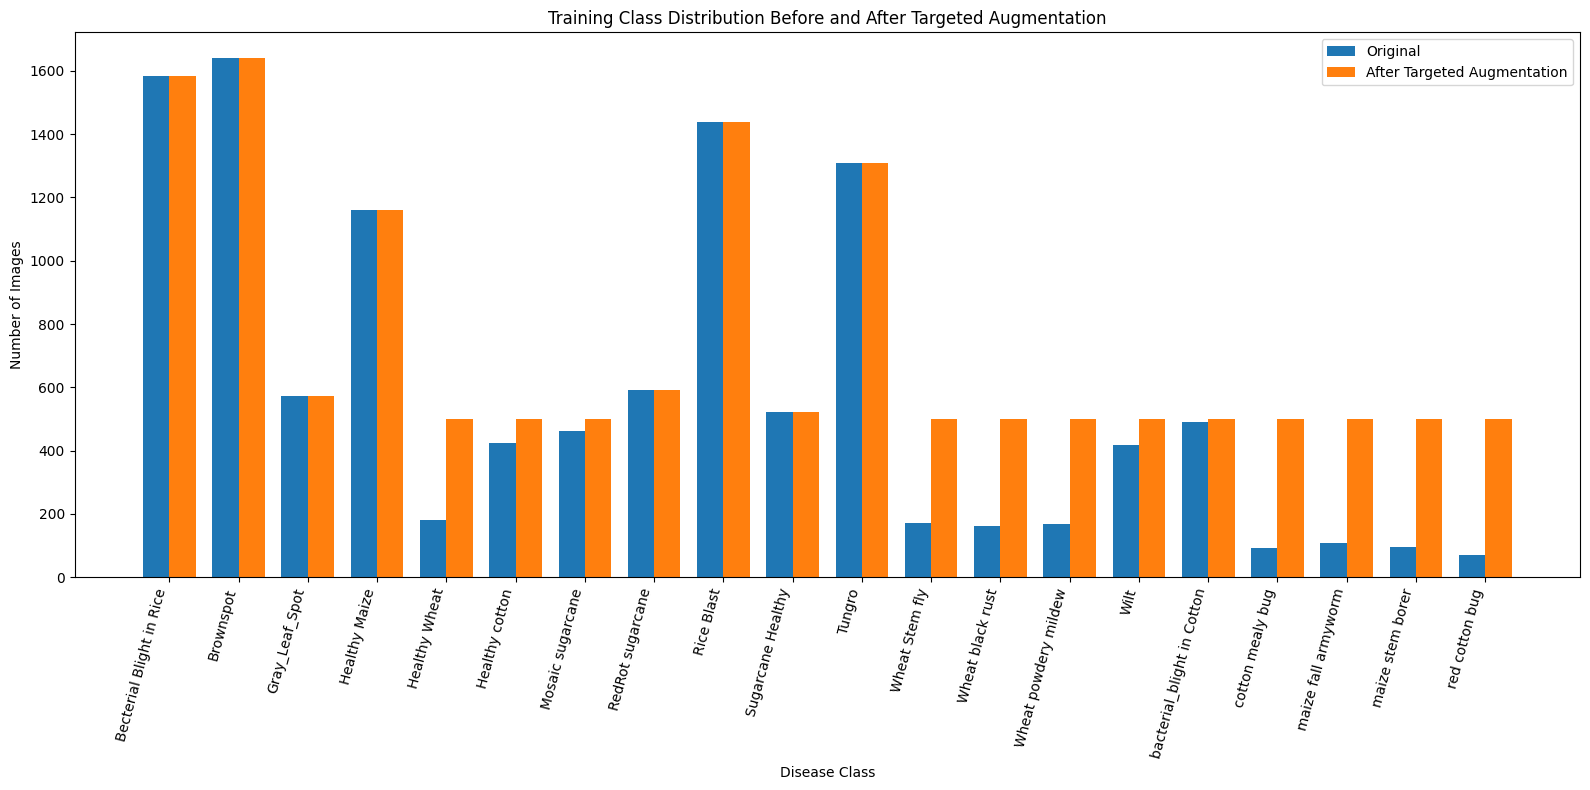

In [40]:
# ============================================
# MEMBER 3 - BEFORE vs AFTER AUGMENTATION
# ============================================

# Create final counts for all 20 classes
final_distribution = class_distribution.copy()

# Add augmented samples to classes that received targeted augmentation
final_distribution["Augmented_Count"] = (
    final_distribution["Additional_Images_Needed"]
)

final_distribution["Final_Count"] = (
    final_distribution["Image_Count"]
    + final_distribution["Augmented_Count"]
)

# Sort alphabetically by class for a clean chart
final_distribution = final_distribution.sort_values(
    "Class"
).reset_index(drop=True)

# Plot
x = np.arange(len(final_distribution))
width = 0.38

plt.figure(figsize=(16, 8))

plt.bar(
    x - width / 2,
    final_distribution["Image_Count"],
    width,
    label="Original"
)

plt.bar(
    x + width / 2,
    final_distribution["Final_Count"],
    width,
    label="After Targeted Augmentation"
)

plt.xticks(
    x,
    final_distribution["Class"],
    rotation=75,
    ha="right"
)

plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.title(
    "Training Class Distribution Before and After Targeted Augmentation"
)

plt.legend()

plt.tight_layout()

plt.show()

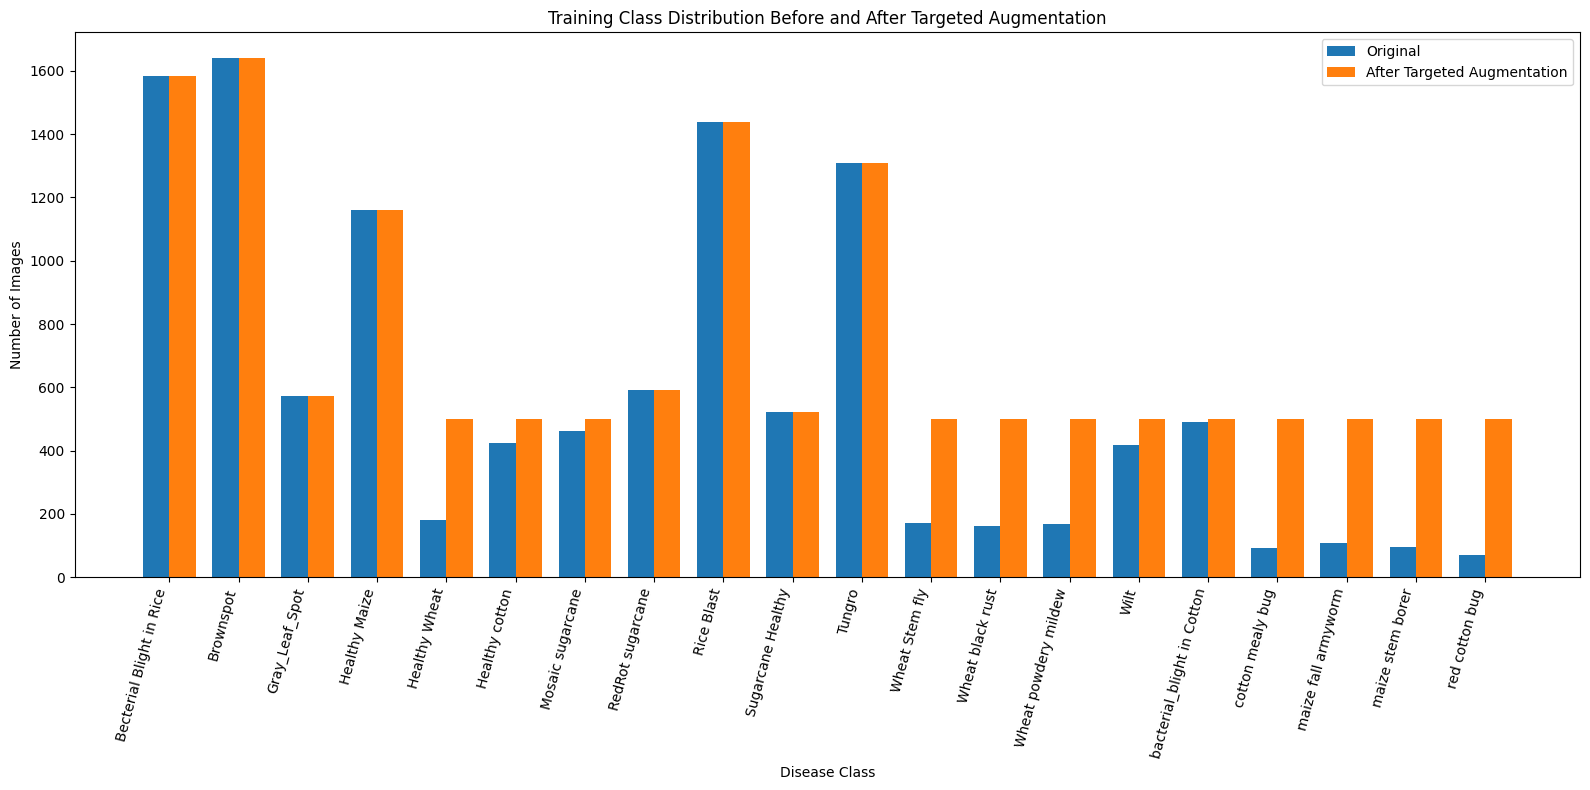

✅ Chart saved successfully!
/content/drive/MyDrive/Crop Disease AI project/Member_03_IT25103371/EDA/class_distribution_before_after_augmentation.png


In [41]:
# Save the before-vs-after distribution chart

before_after_path = os.path.join(
    MEMBER3_EDA,
    "class_distribution_before_after_augmentation.png"
)

plt.figure(figsize=(16, 8))

plt.bar(
    x - width / 2,
    final_distribution["Image_Count"],
    width,
    label="Original"
)

plt.bar(
    x + width / 2,
    final_distribution["Final_Count"],
    width,
    label="After Targeted Augmentation"
)

plt.xticks(
    x,
    final_distribution["Class"],
    rotation=75,
    ha="right"
)

plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.title(
    "Training Class Distribution Before and After Targeted Augmentation"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    before_after_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Chart saved successfully!")
print(before_after_path)

In [42]:
# ============================================
# MEMBER 3 - AUGMENTED IMAGE QUALITY CHECK
# ============================================

import random

# Find all generated .npy files
augmented_files = []

for root, dirs, files in os.walk(TARGETED_AUG_PATH):
    for file in files:
        if file.endswith(".npy"):
            augmented_files.append(
                os.path.join(root, file)
            )

print("Total augmented files found:", len(augmented_files))

# Randomly select up to 10 files for checking
sample_files = random.sample(
    augmented_files,
    min(10, len(augmented_files))
)

print("\nChecking", len(sample_files), "random augmented images...\n")

for file_path in sample_files:

    image = np.load(file_path)

    print(
        os.path.basename(file_path),
        "| Shape:", image.shape,
        "| Dtype:", image.dtype,
        "| Min:", image.min(),
        "| Max:", image.max()
    )

Total augmented files found: 3160

Checking 10 random augmented images...

aug_0091.npy | Shape: (224, 224, 3) | Dtype: float32 | Min: 0.015326905 | Max: 0.9780662
aug_0250.npy | Shape: (224, 224, 3) | Dtype: float32 | Min: 0.00017406794 | Max: 0.99634665
aug_0072.npy | Shape: (224, 224, 3) | Dtype: float32 | Min: 0.00031627622 | Max: 0.99890554
aug_0289.npy | Shape: (224, 224, 3) | Dtype: float32 | Min: 0.039203245 | Max: 1.0
aug_0257.npy | Shape: (224, 224, 3) | Dtype: float32 | Min: 0.0 | Max: 0.99992514
aug_0020.npy | Shape: (224, 224, 3) | Dtype: float32 | Min: 0.08329857 | Max: 1.0
aug_0364.npy | Shape: (224, 224, 3) | Dtype: float32 | Min: 0.15398212 | Max: 0.9924149
aug_0032.npy | Shape: (224, 224, 3) | Dtype: float32 | Min: 0.02296877 | Max: 1.0
aug_0283.npy | Shape: (224, 224, 3) | Dtype: float32 | Min: 0.0 | Max: 0.9998287
aug_0270.npy | Shape: (224, 224, 3) | Dtype: float32 | Min: 0.03130289 | Max: 0.7389388


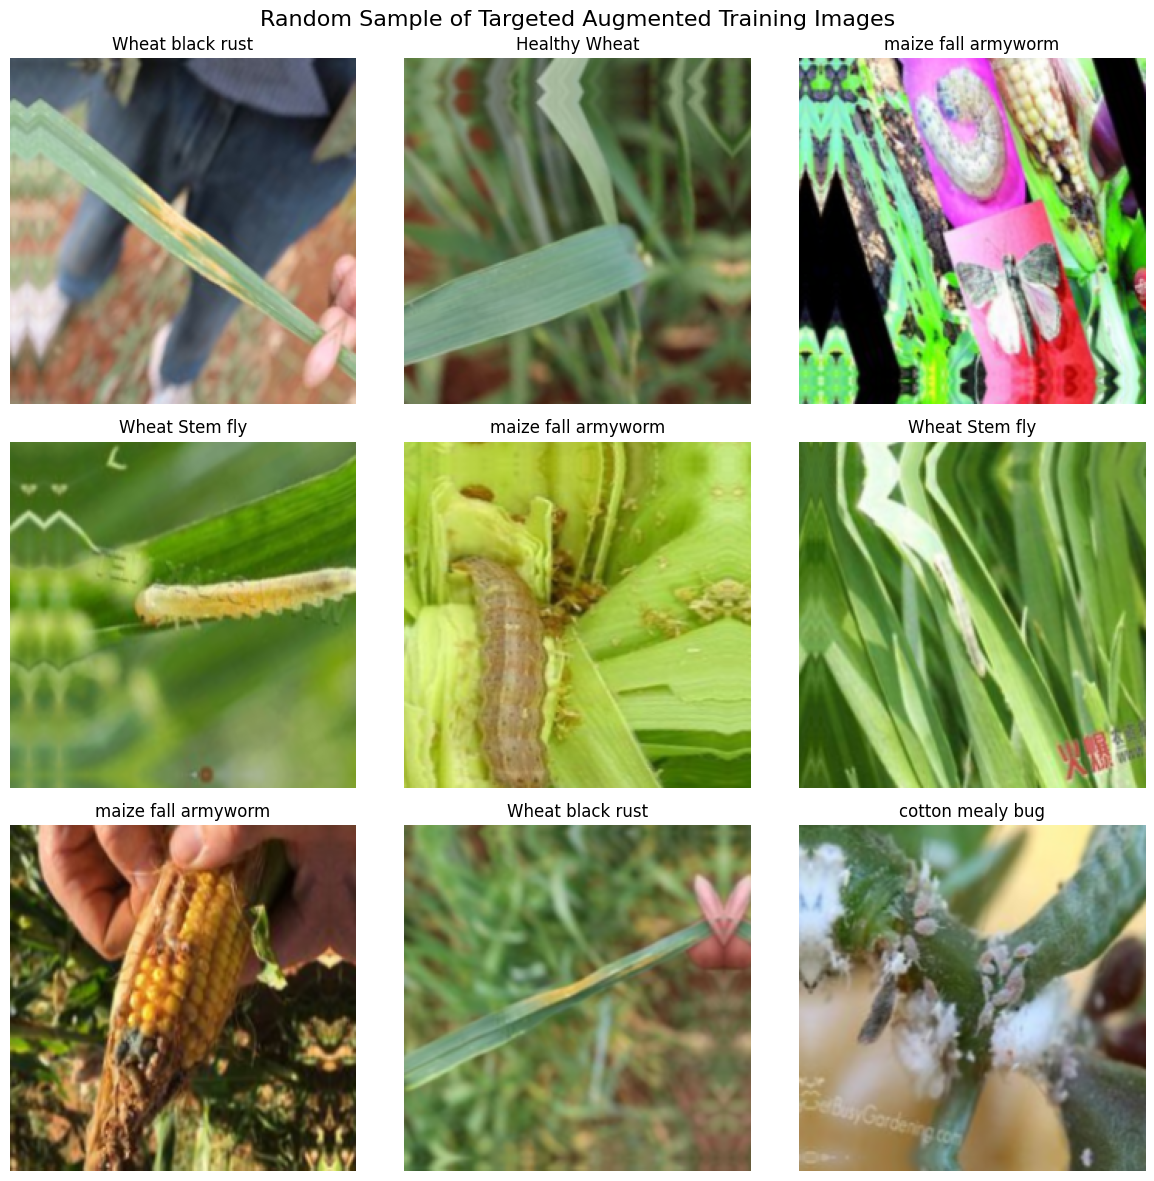

In [43]:
# ============================================
# VISUAL CHECK OF TARGETED AUGMENTED IMAGES
# ============================================

sample_files = random.sample(
    augmented_files,
    min(9, len(augmented_files))
)

plt.figure(figsize=(12, 12))

for i, file_path in enumerate(sample_files):

    image = np.load(file_path)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(
        os.path.basename(
            os.path.dirname(file_path)
        )
    )
    plt.axis("off")

plt.suptitle(
    "Random Sample of Targeted Augmented Training Images",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [44]:
# ============================================
# MEMBER 3 - FINAL AUGMENTATION SUMMARY
# ============================================

summary_data = {
    "Item": [
        "Input Dataset",
        "Original Training Images",
        "Image Size",
        "Image Channels",
        "Pixel Range",
        "Number of Classes",
        "Minority Classes",
        "Target Count per Minority Class",
        "Additional Augmented Images",
        "Final Training Images",
        "Validation Augmentation"
    ],

    "Value": [
        "Member 02_IT25103229 normalized training dataset",
        11662,
        "224 x 224",
        "RGB (3 channels)",
        "0 - 1",
        20,
        12,
        500,
        3160,
        11662 + 3160,
        "Not applied"
    ]
}

augmentation_summary = pd.DataFrame(summary_data)

display(augmentation_summary)

,Item,Value
0,Input Dataset,Member 02_IT25103229 normalized training dataset
1,Original Training Images,11662
2,Image Size,224 x 224
3,Image Channels,RGB (3 channels)
4,Pixel Range,0 - 1
5,Number of Classes,20
6,Minority Classes,12
7,Target Count per Minority Class,500
8,Additional Augmented Images,3160
9,Final Training Images,14822


In [45]:
# Save final augmentation summary

summary_path = os.path.join(
    MEMBER3_OUTPUTS,
    "augmentation_summary.csv"
)

augmentation_summary.to_csv(
    summary_path,
    index=False
)

print("✅ Augmentation summary saved!")
print(summary_path)

✅ Augmentation summary saved!
/content/drive/MyDrive/Crop Disease AI project/Member_03_IT25103371/Outputs/augmentation_summary.csv


In [46]:
# ============================================
# SAVE AUGMENTATION METHODOLOGY
# ============================================

methodology = """
MEMBER 3 - CROP DISEASE AI
DATA AUGMENTATION METHODOLOGY

Input Dataset:
The normalized training dataset produced by Member 2
was used as the input dataset.

Original Training Dataset:
11,662 images

Image Format:
224 x 224 RGB

Pixel Range:
0 to 1

Number of Classes:
20

Class Imbalance:
The training dataset contained significant class imbalance.
The class sizes ranged from 69 images to 1,640 images.

Targeted Augmentation Strategy:
Classes containing fewer than 500 original training images
were selected for targeted augmentation.

Number of Minority Classes:
12

Target:
500 images per minority class.

Additional Augmented Images Generated:
3,160

Augmentation Techniques:
1. Horizontal flipping
2. Random rotation
3. Random zoom
4. Random translation

The augmented images were generated from the original
training images belonging to the minority classes.

Validation Data:
Validation images were NOT augmented.

Data Integrity:
The original Member 2 dataset was not modified.
Augmented data was stored separately in Member 3's
Outputs folder.

Augmentation Approach:
Targeted augmented samples were saved separately as
individual NumPy files to avoid loading the complete
multi-gigabyte dataset into RAM.
"""

methodology_path = os.path.join(
    MEMBER3_OUTPUTS,
    "augmentation_methodology.txt"
)

with open(
    methodology_path,
    "w",
    encoding="utf-8"
) as f:
    f.write(methodology)

print("✅ Methodology file saved!")
print(methodology_path)

✅ Methodology file saved!
/content/drive/MyDrive/Crop Disease AI project/Member_03_IT25103371/Outputs/augmentation_methodology.txt


In [47]:
# ============================================
# MEMBER 3 - FINAL CLASS DISTRIBUTION CHECK
# ============================================

# Start with original class counts
final_check = class_distribution[
    ["Class", "Image_Count"]
].copy()

final_check = final_check.rename(
    columns={"Image_Count": "Original_Count"}
)

# Add targeted augmented counts
augmented_counts = targeted_plan[
    ["Class", "Additional_Images_Needed"]
].copy()

augmented_counts = augmented_counts.rename(
    columns={
        "Additional_Images_Needed":
        "Augmented_Count"
    }
)

# Merge
final_check = final_check.merge(
    augmented_counts,
    on="Class",
    how="left"
)

# Classes without targeted augmentation get 0
final_check["Augmented_Count"] = (
    final_check["Augmented_Count"]
    .fillna(0)
    .astype(int)
)

# Calculate final count
final_check["Final_Count"] = (
    final_check["Original_Count"]
    + final_check["Augmented_Count"]
)

# Sort by final count
final_check = final_check.sort_values(
    "Final_Count",
    ascending=False
).reset_index(drop=True)

display(final_check)

print("===================================")
print("Original training images:",
      final_check["Original_Count"].sum())

print("Additional augmented images:",
      final_check["Augmented_Count"].sum())

print("Final training images:",
      final_check["Final_Count"].sum())
print("===================================")

,Class,Original_Count,Augmented_Count,Final_Count
0,Brownspot,1640,0,1640
1,Becterial Blight in Rice,1584,0,1584
2,Rice Blast,1440,0,1440
3,Tungro,1308,0,1308
4,Healthy Maize,1162,0,1162
5,RedRot sugarcane,592,0,592
6,Gray_Leaf_Spot,574,0,574
7,Sugarcane Healthy,522,0,522
8,bacterial_blight in Cotton,489,11,500
9,Mosaic sugarcane,462,38,500


Original training images: 11662
Additional augmented images: 3160
Final training images: 14822


In [48]:
# ============================================
# MEMBER 3 - FINAL CLASS DISTRIBUTION CHECK
# ============================================

# Start with original class counts
final_check = class_distribution[
    ["Class", "Image_Count"]
].copy()

final_check = final_check.rename(
    columns={"Image_Count": "Original_Count"}
)

# Add targeted augmented counts
augmented_counts = targeted_plan[
    ["Class", "Additional_Images_Needed"]
].copy()

augmented_counts = augmented_counts.rename(
    columns={
        "Additional_Images_Needed":
        "Augmented_Count"
    }
)

# Merge
final_check = final_check.merge(
    augmented_counts,
    on="Class",
    how="left"
)

# Classes without targeted augmentation get 0
final_check["Augmented_Count"] = (
    final_check["Augmented_Count"]
    .fillna(0)
    .astype(int)
)

# Calculate final count
final_check["Final_Count"] = (
    final_check["Original_Count"]
    + final_check["Augmented_Count"]
)

# Sort by final count
final_check = final_check.sort_values(
    "Final_Count",
    ascending=False
).reset_index(drop=True)

display(final_check)

print("===================================")
print("Original training images:",
      final_check["Original_Count"].sum())

print("Additional augmented images:",
      final_check["Augmented_Count"].sum())

print("Final training images:",
      final_check["Final_Count"].sum())
print("===================================")

,Class,Original_Count,Augmented_Count,Final_Count
0,Brownspot,1640,0,1640
1,Becterial Blight in Rice,1584,0,1584
2,Rice Blast,1440,0,1440
3,Tungro,1308,0,1308
4,Healthy Maize,1162,0,1162
5,RedRot sugarcane,592,0,592
6,Gray_Leaf_Spot,574,0,574
7,Sugarcane Healthy,522,0,522
8,bacterial_blight in Cotton,489,11,500
9,Mosaic sugarcane,462,38,500


Original training images: 11662
Additional augmented images: 3160
Final training images: 14822


In [50]:
final_check_path = os.path.join(
    MEMBER3_OUTPUTS,
    "final_training_class_distribution.csv"
)

final_check.to_csv(
    final_check_path,
    index=False
)

print("✅ Final class distribution saved!")
print(final_check_path)

✅ Final class distribution saved!
/content/drive/MyDrive/Crop Disease AI project/Member_03_IT25103371/Outputs/final_training_class_distribution.csv
✅ Final class distribution saved!
/content/drive/MyDrive/Crop Disease AI project/Member_03_IT25103371/Outputs/final_training_class_distribution.csv


In [51]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Crop Disease AI project"
MEMBER3_PATH = os.path.join(PROJECT_PATH, "Member_03_IT25103371")

CODE_PATH = os.path.join(MEMBER3_PATH, "Code")
NOTEBOOK_PATH = os.path.join(MEMBER3_PATH, "Notebook")

os.makedirs(CODE_PATH, exist_ok=True)
os.makedirs(NOTEBOOK_PATH, exist_ok=True)

print("Code folder:", CODE_PATH)
print("Notebook folder:", NOTEBOOK_PATH)

Code folder: /content/drive/MyDrive/Crop Disease AI project/Member_03_IT25103371/Code
Notebook folder: /content/drive/MyDrive/Crop Disease AI project/Member_03_IT25103371/Notebook


In [52]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [53]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Crop Disease AI project"
MEMBER3_PATH = os.path.join(PROJECT_PATH, "Member_03_IT25103371")

CODE_PATH = os.path.join(MEMBER3_PATH, "Code")
NOTEBOOK_PATH = os.path.join(MEMBER3_PATH, "Notebook")

os.makedirs(CODE_PATH, exist_ok=True)
os.makedirs(NOTEBOOK_PATH, exist_ok=True)

print("Code:", CODE_PATH)
print("Notebook:", NOTEBOOK_PATH)

Code: /content/drive/MyDrive/Crop Disease AI project/Member_03_IT25103371/Code
Notebook: /content/drive/MyDrive/Crop Disease AI project/Member_03_IT25103371/Notebook
